In [10]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset

In [11]:
class MVTecDataset(Dataset):
    def __init__(self, root_dir: str, category: str, mode:str = 'train', transform=None, mask_transform=None):
        """
        Args:
            root_dir (string): Directory with all the images
            category: Name of the class to load (e.g., 'bottle', 'cable', etc.)
            mode: 'train' (only normal images) or 'test' (normal or anomalous images)
            transform: transforms for input images
            mask_transform: transforms for mask images
        """
        self.root_dir = root_dir
        self.category = category
        self.class_dir = os.path.join(root_dir, category)
        self.mode = mode
        self.transform = transform
        self.mask_transform = mask_transform

        self.image_paths = []
        self.mask_paths = []
        self.labels = []        # 0 for normal, 1 for anomalous

        self._load_dataset_paths()

    def _load_dataset_paths(self):
        if self.mode == 'train':
            img_dir = os.path.join(self.class_dir, 'train', 'good')
            for img_name in sorted(os.listdir(img_dir)):
                if not img_name.endswith(('.png', '.jpg', '.jpeg', '.tiff', '.bmp')):
                    continue
                self.image_paths.append(os.path.join(img_dir, img_name))
                self.mask_paths.append(None)        # No masks for training images
                self.labels.append(0)               # All training images are normal
        
        elif self.mode == 'test':
            test_dir = os.path.join(self.class_dir, 'test')
            gt_dir = os.path.join(self.class_dir, 'ground_truth')

            for defect_type in sorted(os.listdir(test_dir)):
                defect_dir = os.path.join(test_dir, defect_type)
                if not os.path.isdir(defect_dir):
                    continue

                for img_name in sorted(os.listdir(defect_dir)):
                    if not img_name.endswith(('.png', '.jpg', '.jpeg', '.tiff', '.bmp')):
                        continue
                    img_path = os.path.join(defect_dir, img_name)
                    self.image_paths.append(img_path)

                    if defect_type == 'good':
                        self.mask_paths.append(None)    # No masks for normal images
                        self.labels.append(0)           # Normal image
                    else:
                        mask_name = os.path.splitext(img_name)[0] + '_mask.png'
                        mask_path = os.path.join(gt_dir, defect_type, mask_name)
                        self.mask_paths.append(mask_path)
                        self.labels.append(1)           # Anomalous image
    

    def __len__(self):
        return len(self.image_paths)
    

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)
        
        mask_path = self.mask_paths[idx]
        if mask_path:
            mask = Image.open(mask_path).convert('L')       # Masks are single channel
            if self.mask_transform:
                mask = self.mask_transform(mask)
        else:
            if isinstance(image, torch.Tensor):
                mask = torch.zeros((1, image.shape[1], image.shape[2]))
            else:
                mask = torch.zeros((1, image.size[1], image.size[0]))
        
        label = torch.tensor(self.labels[idx], dtype=torch.float32)

        return image, mask, label, img_path

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms

Anomalous image: D:/Unsupervised-Anomaly-Detection-Using-Autoencoder-Architecture/data\bottle\test\broken_large\000.png


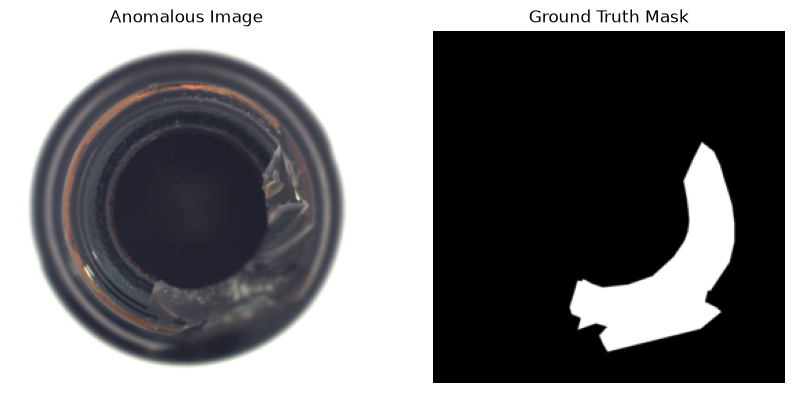

In [15]:
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

dataset = MVTecDataset(root_dir='D:/Unsupervised-Anomaly-Detection-Using-Autoencoder-Architecture/data',
                    category='bottle',
                    mode='test',
                    transform=transform,
                    mask_transform=transform)

for i in range(len(dataset)):
    img, mask, label, img_path = dataset[i]

    if label == 1:
        print(f"Anomalous image: {img_path}")

        img_np = img.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze().numpy()

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img_np)
        axes[0].set_title("Anomalous Image")
        axes[0].axis('Off')

        axes[1].imshow(mask_np, cmap='gray')
        axes[1].set_title("Ground Truth Mask")
        axes[1].axis('Off')

        plt.show()
        break